# 3. Modelado supervisado, pesos y evaluación

Esta fase ejecuta200ajustes máximos en desarrollo: sensibilidad de pesos por familia y búsqueda acotada de seis configuraciones por familia, con los mismos cinco folds agrupados. Puede tardar varios minutos; el tiempo real queda registrado.

In [1]:
from pathlib import Path
import os,sys,json,subprocess,time
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
assert (ROOT/'src/run_analysis.py').exists(), 'Abra el notebook dentro del proyecto'
os.environ['MPLCONFIGDIR']=str(ROOT/'tmp/matplotlib')
os.environ['XDG_CACHE_HOME']=str(ROOT/'tmp/cache')
sys.path.insert(0,str(ROOT/'src'))
def run_script(name,*args):
    started=time.perf_counter()
    result=subprocess.run([sys.executable,str(ROOT/'src'/name),*map(str,args)],cwd=ROOT,text=True,capture_output=True)
    (ROOT/'reports').mkdir(exist_ok=True)
    (ROOT/'reports'/f'notebook_{name}_{Path(str(args[-1])).name if args else "run"}.log').write_text(result.stdout+result.stderr)
    print(result.stdout[-4500:].replace(str(ROOT),'${PROJECT_ROOT}').replace(str(Path.home()),'${HOME}'))
    if result.returncode: print(result.stderr); result.check_returncode()
    print(f'Ejecución real completada en {time.perf_counter()-started:.1f} segundos')
def show(name): display(Image(filename=str(ROOT/'reports/figures'/name)))
def table(name): display(pd.read_csv(ROOT/'reports/tables'/name).head(20))
def results(): return json.loads((ROOT/'reports/results.json').read_text())
print('Python:',sys.version.split()[0], '| kernel del entorno del proyecto')


Python: 3.12.14 | kernel del entorno del proyecto


## Protocolo y configuraciones
La selección usa AP ponderada de validación. La prueba heredada ya se observó en una versión anterior; se conserva por comparabilidad y esta revisión es retrospectiva. Nunca se cambia el ganador según prueba.

In [2]:
from run_analysis import models_config,assert_features
for name,model,configs in models_config(): print(name,configs)
display(Markdown((ROOT/'docs/MODELING_PROTOCOL.md').read_text()))

Logística [{'C': 0.01}, {'C': 0.03}, {'C': 0.1}, {'C': 0.3}, {'C': 1.0}, {'C': 3.0}]
Random Forest [{'max_depth': 8, 'min_samples_leaf': 10, 'max_features': 'sqrt'}, {'max_depth': None, 'min_samples_leaf': 6, 'max_features': 'sqrt'}, {'max_depth': 12, 'min_samples_leaf': 4, 'max_features': 0.7}, {'max_depth': 8, 'min_samples_leaf': 6, 'max_features': 0.7}, {'max_depth': None, 'min_samples_leaf': 12, 'max_features': 0.7}, {'max_depth': 16, 'min_samples_leaf': 3, 'max_features': 'sqrt'}]
XGBoost [{'max_depth': 2, 'min_child_weight': 1, 'reg_lambda': 5}, {'max_depth': 3, 'min_child_weight': 1, 'reg_lambda': 5}, {'max_depth': 5, 'min_child_weight': 1, 'reg_lambda': 5}, {'max_depth': 3, 'min_child_weight': 5, 'reg_lambda': 10}, {'max_depth': 4, 'min_child_weight': 5, 'reg_lambda': 10}, {'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 1}]
CatBoost [{'depth': 3, 'l2_leaf_reg': 3}, {'depth': 4, 'l2_leaf_reg': 6}, {'depth': 6, 'l2_leaf_reg': 6}, {'depth': 4, 'l2_leaf_reg': 12}, {'depth': 5

${PROJECT_ROOT}/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Protocolo de revisión fijado antes del nuevo entrenamiento

Se conserva la pregunta operacional, los13predictores, las cuatro familias, el split por conglomerado con semilla42 y los mismos5folds. La decisión final sobre las fuentes y el objetivo precede a la ejecución supervisada.

## Búsqueda acotada en desarrollo

1. Por familia se compara una configuración representativa bajo cuatro estrategias: uniforme, expansión poblacional, balance de clases y expansión con balance. La normalización y el balance se calculan en el subconjunto de ajuste de cada fold. Las cuatro estrategias se comparan por AP media de los cinco folds, ponderada por FACPOB07.
2. Se fija la estrategia de mayor AP para cada familia; se prueban seis configuraciones de hiperparámetros por familia sobre los mismos folds. El código `models_config` enumera exactamente24configuraciones.
3. Se elige la familia/configuración con mayor AP-CV media. El máximo presupuesto son200ajustes:80de sensibilidad y120de hiperparámetros. No es optimización conjunta ni exhaustiva. El sesgo de selección de CV permanece y se declara.
4. Las probabilidades OOF de la configuración elegida por familia entrenan un calibrador sigmoide con pesos poblacionales. El calibrador no ve prueba. El umbral principal permanece0.5; no se optimiza en prueba.
5. Se ajusta cada modelo con desarrollo y se evalúa en prueba. Se guardan todos los resultados, sin sustituir al ganador por una métrica de prueba. Se añaden predictores constantes (mayoría y prevalencia de desarrollo) y métricas ponderadas/no ponderadas. AP y áreaPRtrapezoidal son distintos.

Rangos: logística C0.01–3 contempla regularización fuerte/moderada; RF profundidad8–ilimitada, hojas3–12 y fracción de características; XGBoost profundidades2–5, peso mínimo de hoja y penalización; CatBoost profundidades3–6 y L2. Árboles limitados a180/260/300 y4hilos para CPU. No se aumenta el presupuesto según el resultado de prueba.

## Clustering y explicación

Se conserva KMeans/GMM k2–6 con preprocesamiento en desarrollo, mínima masa5%, máxima silueta y DB como desempate. Se agrega estabilidad ARI por semillas42–44 y submuestras80%, además de ablación sin electricidad/internet al mismo método/k. Los perfiles se describen después de formar grupos; la etiqueta no determina la selección.

SHAP explica el ganador real antes de calibrar. Se añade XGBoost como análisis no lineal explícito con interaccionesTreeSHAP en hasta180casos de prueba, semilla42; se agrupan dummies mediante suma de contribuciones y bloques de interacción. Se escogen exploratoriamente los dos pares con mayor contribución absoluta entre variables territoriales, lengua, acceso y condiciones económicas. No se atribuyen causalidad ni significación estadística a estos pares.

## Límite de la evaluación

La prueba se observó en la versión anterior. La nueva selección no utiliza sus valores, pero no puede considerarse una evaluación inédita ni externa. Se mantiene la partición para comparar versiones y se declara el carácter retrospectivo de esta auditoría. Una nueva fuente temporal o muestra externa sería necesaria para una validación independiente posterior.


## Entrenamiento y calibración reales
Cada fold ajusta su imputación, escalado y one-hot exclusivamente en entrenamiento. Se calibra con predicciones OOF de desarrollo y pesos de población. El umbral principal permanece0.5.

In [3]:
run_script('run_analysis.py','--phase','supervised')
print('Ganador CV:',results()['supervised']['winner'])
table('weight_sensitivity.csv')
table('model_comparison_cv.csv')
table('model_comparison_test.csv')
table('constant_baselines_test.csv')

Cohorte y particiones 13105 3439
Pesos Logística uniform
Pesos Random Forest uniform
Pesos XGBoost uniform
Pesos CatBoost class
CV Logística 1 fold 1
CV Logística 1 fold 2
CV Logística 1 fold 3
CV Logística 1 fold 4
CV Logística 1 fold 5
CV Logística 2 fold 1
CV Logística 2 fold 2
CV Logística 2 fold 3
CV Logística 2 fold 4
CV Logística 2 fold 5
CV Logística 3 fold 1
CV Logística 3 fold 2
CV Logística 3 fold 3
CV Logística 3 fold 4
CV Logística 3 fold 5
CV Logística 4 fold 1
CV Logística 4 fold 2
CV Logística 4 fold 3
CV Logística 4 fold 4
CV Logística 4 fold 5
CV Logística 5 fold 1
CV Logística 5 fold 2
CV Logística 5 fold 3
CV Logística 5 fold 4
CV Logística 5 fold 5
CV Logística 6 fold 1
CV Logística 6 fold 2
CV Logística 6 fold 3
CV Logística 6 fold 4
CV Logística 6 fold 5
CV Random Forest 1 fold 1
CV Random Forest 1 fold 2
CV Random Forest 1 fold 3
CV Random Forest 1 fold 4
CV Random Forest 1 fold 5
CV Random Forest 2 fold 1
CV Random Forest 2 fold 2
CV Random Forest 2 fold 3
CV R

,modelo,estrategia,ap_cv_media,ap_oof_no_ponderada,brier_oof_ponderado,ap_oof_peso_educacion,segundos
0,Logística,uniform,0.587467,0.663590,0.133100,0.596697,0.143155
1,Logística,population,0.585403,0.656499,0.133430,0.594859,0.134935
2,Logística,class,0.587352,0.663120,0.162730,0.596782,0.147111
3,Logística,population_class,0.584980,0.656331,0.176369,0.594983,0.147011
4,Random Forest,uniform,0.579663,0.656160,0.136733,0.588209,1.566843
5,Random Forest,population,0.575059,0.654547,0.137762,0.585580,1.491718
6,Random Forest,class,0.576868,0.654884,0.165290,0.586403,1.556953
7,Random Forest,population_class,0.572174,0.651187,0.177465,0.583393,1.425203
8,XGBoost,uniform,0.591181,0.669177,0.132491,0.601713,0.640642
9,XGBoost,population,0.581843,0.658719,0.133631,0.592615,0.650512


,modelo,config,parametros,ap_cv_media,ap_cv_sd,auc_cv_media,f1_cv_media,estrategia_peso,segundos
0,CatBoost,0,"{""depth"": 3, ""l2_leaf_reg"": 3}",0.592834,0.011725,0.818080,0.700747,class,1.791255
1,XGBoost,0,"{""max_depth"": 2, ""min_child_weight"": 1, ""reg_l...",0.591181,0.019463,0.817403,0.679507,uniform,0.653599
2,Logística,1,"{""C"": 0.03}",0.588552,0.025634,0.816914,0.670694,uniform,0.153990
3,Random Forest,3,"{""max_depth"": 8, ""min_samples_leaf"": 6, ""max_f...",0.580900,0.022049,0.812014,0.676218,uniform,3.569233


,modelo,seleccionado_cv,roc_auc,average_precision,pr_auc_trapezoidal,f1_macro,precision,recall,brier,specificity,brier_sin_calibrar,f1_macro_no_ponderado,auc_no_ponderado,roc_auc_no_ponderado,average_precision_no_ponderado,pr_auc_trapezoidal_no_ponderado,precision_no_ponderado,recall_no_ponderado,brier_no_ponderado,specificity_no_ponderado
0,Logística,False,0.815614,0.585869,0.585245,0.680088,0.649656,0.368829,0.128950,0.943892,0.128960,0.714429,0.839046,0.839046,0.656319,0.656044,0.663974,0.472957,0.132977,0.919066
1,Random Forest,False,0.815914,0.582622,0.581930,0.672097,0.663154,0.344998,0.129044,0.950566,0.129053,0.711028,0.836213,0.836213,0.649226,0.648892,0.684764,0.449942,0.133665,0.929961
2,XGBoost,False,0.816164,0.593723,0.593140,0.690490,0.670302,0.383738,0.128464,0.946756,0.128597,0.723195,0.840056,0.840056,0.664944,0.664703,0.674603,0.489068,0.131879,0.920233
3,CatBoost,True,0.820282,0.599633,0.599025,0.681567,0.666673,0.364761,0.127433,0.948554,0.161632,0.713637,0.840914,0.840914,0.664402,0.664140,0.675630,0.462601,0.131692,0.924903


,modelo,roc_auc,average_precision,pr_auc_trapezoidal,f1_macro,precision,recall,brier,specificity
0,Mayoritario,0.5,0.220024,0.610012,0.438195,0.0,0.0,0.220024,1.0
1,Prevalencia desarrollo,0.5,0.220024,0.610012,0.438195,0.0,0.0,0.171687,1.0


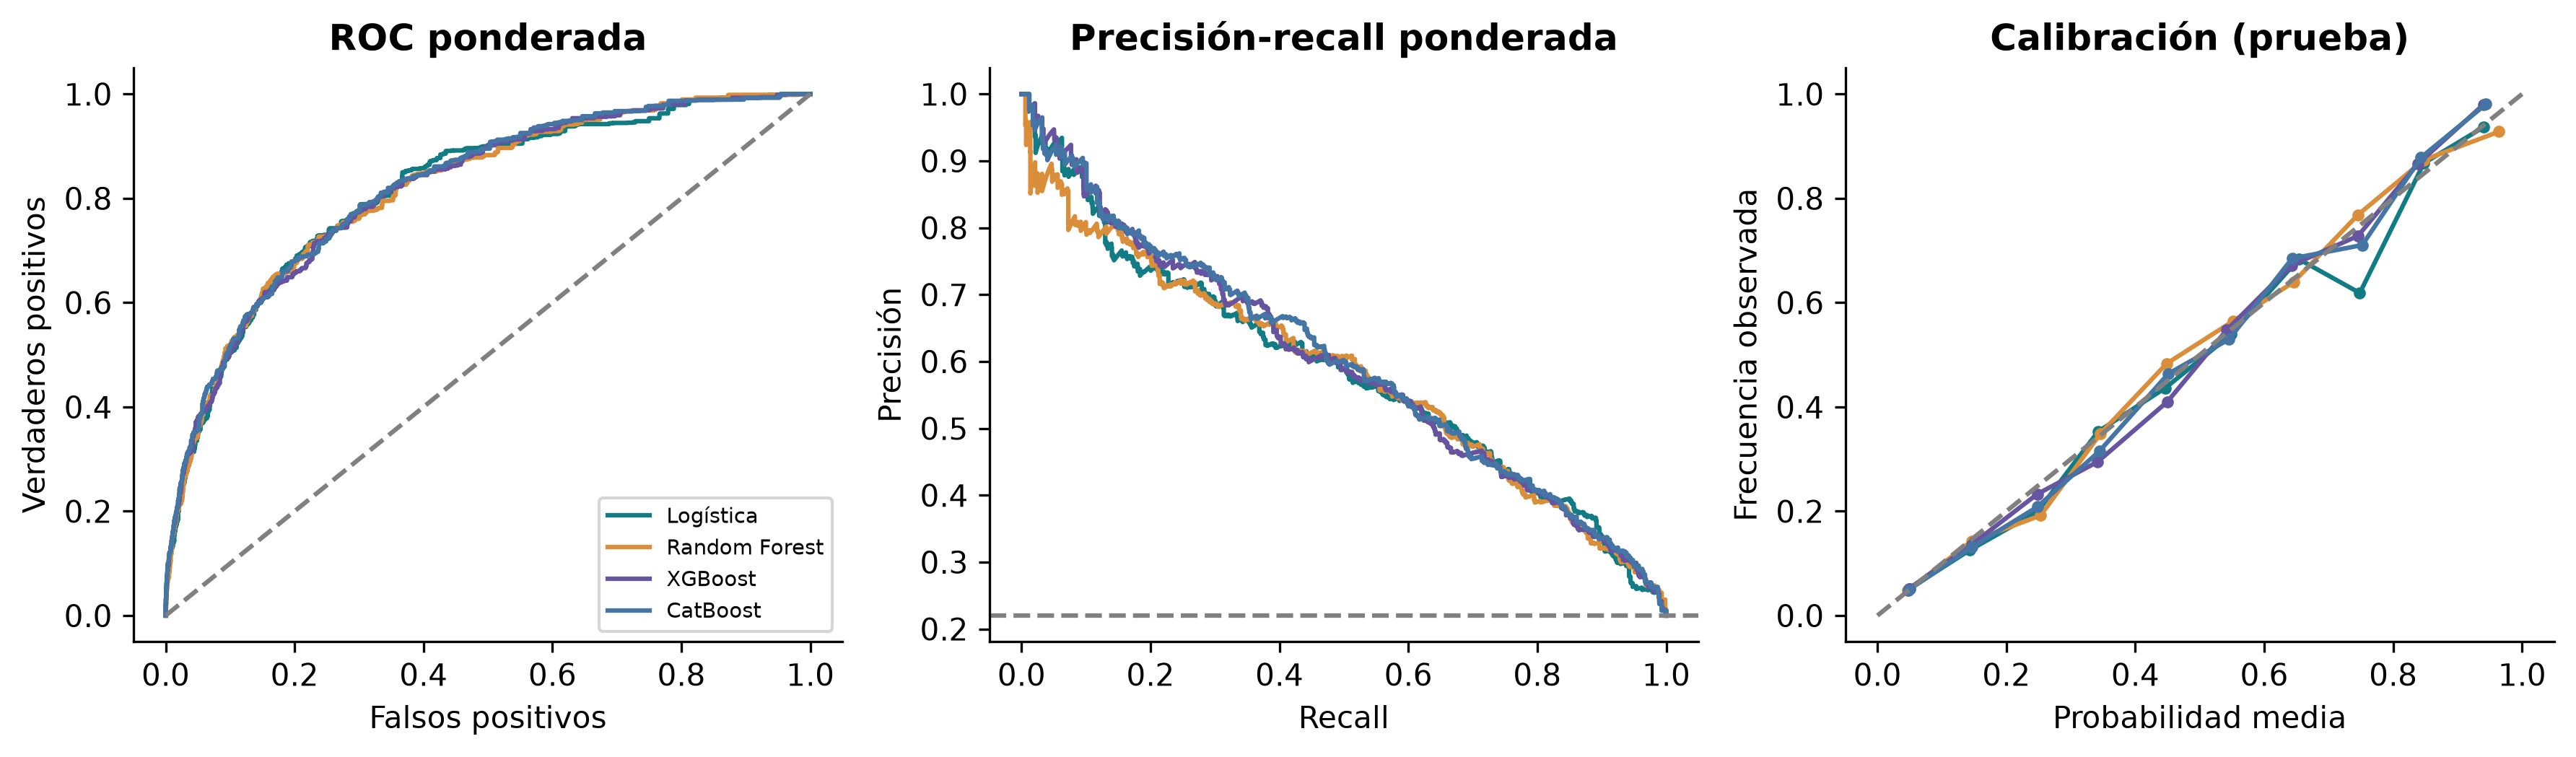

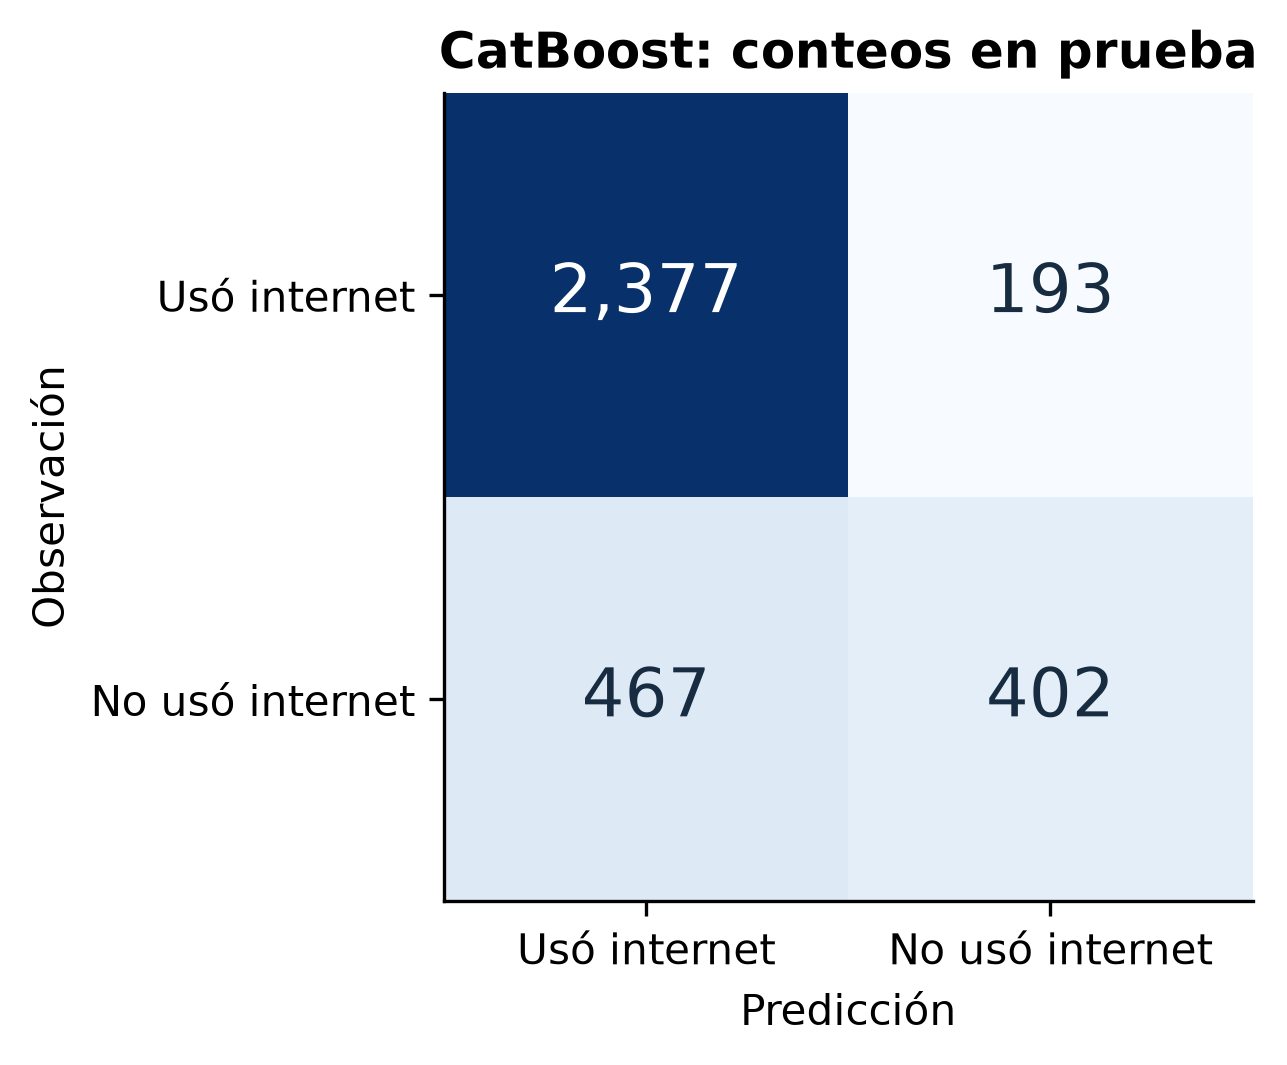

,variable,grupo,n,roc_auc,average_precision,pr_auc_trapezoidal,f1_macro,precision,recall,brier,specificity
0,rural,0.0,2150,0.791065,0.471561,0.469288,0.604181,0.594657,0.199933,0.116947,0.971720
1,rural,1.0,1289,0.823817,0.755767,0.755291,0.732701,0.710838,0.632116,0.167372,0.826056
2,sexo,1.0,1739,0.807812,0.596332,0.595183,0.667046,0.665136,0.346901,0.138704,0.944665
3,sexo,2.0,1700,0.831801,0.606438,0.605168,0.697150,0.668346,0.386305,0.116164,0.952242
4,lengua_materna,1.0,210,0.787553,0.748065,0.745653,0.719609,0.711357,0.607418,0.184092,0.824668
5,lengua_materna,3.0,46,0.727559,0.820451,0.805697,0.693753,0.817442,0.826651,0.195668,0.557856
6,lengua_materna,4.0,3085,0.813150,0.556815,0.555851,0.660469,0.641754,0.316443,0.124022,0.954991
7,pobreza,1.0,198,0.805219,0.853593,0.851721,0.785541,0.872187,0.702590,0.181052,0.881525
8,pobreza,2.0,800,0.772342,0.543964,0.541342,0.653076,0.569883,0.390449,0.160543,0.891567
9,pobreza,3.0,2441,0.820899,0.526695,0.525547,0.634876,0.647163,0.244539,0.108619,0.972817


In [4]:
show('model_curves.png')
show('confusion_matrix.png')
table('subgroup_performance_test.csv')

## Conclusión
AP y áreaPRtrapezoidal son resúmenes diferentes. Discuta recall, especificidad, FP/FN y calibración, además de AUC. La ponderación no reproduce por sí sola todo el diseño complejo. Las diferencias de rendimiento no equivalen automáticamente a significación estadística ni a un uso operativo validado.